Poisson-Kac process - Vibe Coders - Notebook

Task 1

Calculated term for mu: 10.0


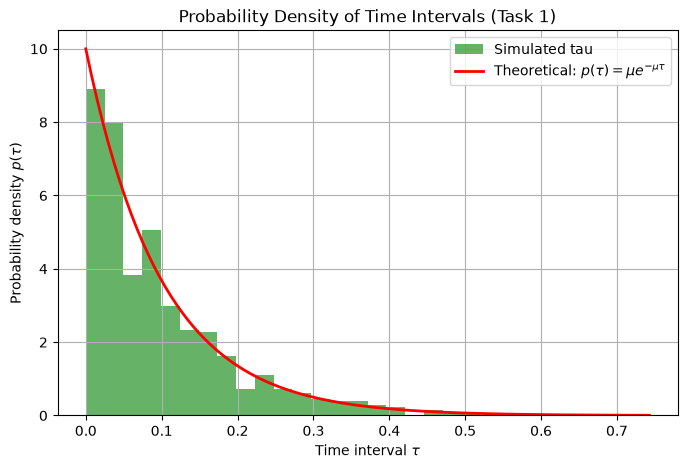

In [3]:
import matplotlib.pyplot as plt
import numpy as np
rng = np.random.default_rng()



def generate_poisson_intervals(N,T):
    t_events=np.sort(rng.uniform(0, T, N))
    tau = np.diff(t_events)
    return tau

def main_function():
    N = 1000
    T = 100

    tau = generate_poisson_intervals(N, T)

    mu = N/T
    print(f"Calculated term for mu: {mu}")

    plt.figure(figsize=(8,5))
    plt.hist(tau, bins=30, density=True, alpha=0.6, color='g', label='Simulated tau')

    tau_theoretical = np.linspace(0, np.max(tau), 100)
    p_tau = mu * np.exp(-mu * tau_theoretical)
    plt.plot(tau_theoretical, p_tau, "r-", linewidth=2, label=r"Theoretical: $p(\tau) = \mu e^{-\mu\tau}$",
    )

    plt.title("Probability Density of Time Intervals (Task 1)")
    plt.xlabel(r"Time interval $\tau$")
    plt.ylabel(r"Probability density $p(\tau)$")
    plt.legend()
    plt.grid(True)
    plt.savefig("task1_distribution.png")
    plt.show()


main_function()

Task 2

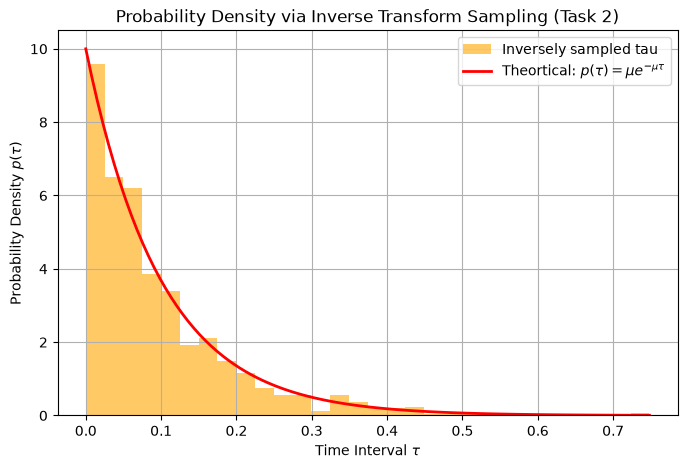

In [4]:
import matplotlib.pyplot as plt
import numpy as np

rng=np.random.default_rng()

def generate_inverse_exponential(N, mu):
    P = rng.uniform(0, 1, N)
    tau = -np.log(1-P) / mu
    return tau

def main_function():
    N = 1000
    T = 100
    mu = N / T
    tau = generate_inverse_exponential(N, mu)

    plt.figure(figsize=(8, 5))
    plt.hist(tau, bins=30, density=True, alpha=0.6, color='orange', label='Inversely sampled tau')

    tau_theoretical = np.linspace(0,np.max(tau), 100)
    p_tau = mu * np.exp(-mu * tau_theoretical)
    plt.plot(tau_theoretical, p_tau, "r-", linewidth=2, label=r"Theortical: $p(\tau) = \mu e^{-\mu\tau}$")

    plt.xlabel(r'Time Interval $\tau$')
    plt.ylabel(r'Probability Density $p(\tau)$')
    plt.title('Probability Density via Inverse Transform Sampling (Task 2)')
    plt.legend()
    plt.grid(True)
    plt.savefig("task2_distribution.png")
    plt.show()

main_function()

Task 3

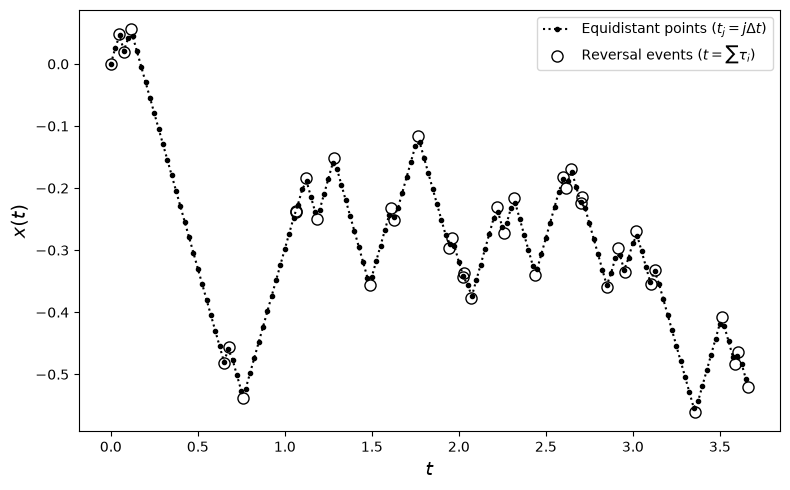

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def generate_event_trajectory(N, rate_mu, speed_s):
    P = np.random.uniform(0, 1, N)
    tau = -np.log(1.0 - P) / rate_mu
  
    t_events = np.zeros(N + 1)
    x_events = np.zeros(N + 1)
    
    current_v = speed_s
    for i in range(N):
        t_events[i + 1] = t_events[i] + tau[i]
        x_events[i + 1] = x_events[i] + current_v * tau[i]
        current_v = -current_v  # Geschwindigkeitsumkehr
        
    return t_events, x_events

def interpolate_equidistant_trajectory(t_events, x_events, speed_s, dt):
    # Erstellt die Trajektorie an äquidistanten Zeitpunkten t_j = j * dt
    t_max = t_events[-1]
    t_grid = np.arange(0, t_max, dt)
    x_grid = np.zeros_like(t_grid)
    
    # Für jeden Zeitpunkt t_j wird die exakte Position durch Stückweise Linearität berechnet
    for j, t in enumerate(t_grid):
        # Finde das Intervall, in dem t liegt
        idx = np.searchsorted(t_events, t, side='right') - 1
        if idx < len(t_events) - 1:
            # Vorzeichen der Geschwindigkeit bestimmen: alternierend (+s, -s, +s, ...)
            v_current = speed_s if (idx % 2 == 0) else -speed_s
            x_grid[j] = x_events[idx] + v_current * (t - t_events[idx])
        else:
            x_grid[j] = x_events[-1]
            
    return t_grid, x_grid

def main_function():
    N = 40
    rate_mu = 10
    speed_s = 1
    dt = 0.25 / rate_mu

    # Event-basierte Trajektorie
    t_events, x_events = generate_event_trajectory(N, rate_mu, speed_s)
    
    # Äquidistante Trajektorie
    t_grid, x_grid = interpolate_equidistant_trajectory(t_events, x_events, speed_s, dt)
    
    # Visualisierung
    plt.figure(figsize=(8, 5))
    
    # Zeichne äquidistante Punkte und gestrichelte Verbindungslinie
    plt.plot(t_grid, x_grid, 'k:.', label='Equidistant points ($t_j = j \\Delta t$)')
    
    # Zeichne Event-Kreise
    plt.plot(t_events, x_events, 'ko', mfc='none', ms=8, label='Reversal events ($t = \\sum \\tau_i$)')
    
    plt.xlabel('$t$', fontsize=14)
    plt.ylabel('$x(t)$', fontsize=14)
    plt.grid(False)
    plt.legend()
    plt.tight_layout()
    plt.savefig('task3_trajectory.png', dpi=300)
    plt.show()

if __name__ == '__main__':
    main_function()